# Assignment 4, Part 3: Preprocessing and word frequencies

Run the cells in order. This notebook loads the Australian company “About Us”
texts, creates versions with and without stopwords, and saves the word-frequency and innovativeness charts plus the final dataset.

If needed, run `%pip install pandas spacy matplotlib` in a separate cell first.
The spaCy model `en_core_web_sm` must also be installed in this notebook's kernel.
The first chunk does this, but you can skip it if you already have it.


In [3]:
import sys
!"{sys.executable}" -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     - ------------------------------------- 0.5/12.8 MB 346.6 kB/s eta 0:00:36
     - ------------------------------------- 0.5/12.8 MB 346.6 kB/s eta 0:00:36
     - ------------------------------------- 0.5/12.8 MB 346.6 kB/s eta 0:00:36
     - ------------------------------------- 0.5/12.8 MB 346.6 kB/s eta 0:00:36
     -- ------------------------------------ 0.8/12.8 MB 310.9 kB/s eta 0:00:39
     -- ------------------------------------ 0.8/12.8 MB 310.9 kB/s eta 0:00:39
     -- ------------------------------------ 0.8/12.8 MB 310.9 kB/s eta 0:00:39
     -- 

In [4]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter
import re

import pandas as pd
import spacy
import matplotlib.pyplot as plt


## Step 1. Locate and load the company texts

Finds the text and unpacks it from the zip


In [5]:
possible_roots = [Path.cwd(), *Path.cwd().parents]
repo_root = next(
    (folder for folder in possible_roots
     if (folder / "tutorials/text_prep_and_dict.ipynb").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Open this notebook from the MAN7916 repository or its assignment_4 folder.")

about_folder = repo_root / "local_data/aussie/About"
output_folder = repo_root / "assignments/submissions/assignment_4"
output_folder.mkdir(parents=True, exist_ok=True)

if not any(about_folder.glob("*.txt")):
    archive_path = repo_root / "corpora/AussieTop100private.zip"
    if not archive_path.is_file():
        raise FileNotFoundError(f"Neither the company texts nor their ZIP archive was found: {archive_path}")
    about_folder.mkdir(parents=True, exist_ok=True)
    with ZipFile(archive_path) as archive:
        for member in archive.infolist():
            if re.fullmatch(r"About/\d+\.txt", member.filename):
                destination = about_folder / Path(member.filename).name
                if not destination.exists():
                    destination.write_bytes(archive.read(member))

text_files = sorted(about_folder.glob("*.txt"), key=lambda path: int(path.stem))
if not text_files:
    raise FileNotFoundError(f"No company text files were found in {about_folder}")

print(f"Found {len(text_files)} company texts in {about_folder}")


Found 77 company texts in c:\Research\Subjects\content analysis\MAN7916-main\local_data\aussie\About


In [6]:
records = []
for filepath in text_files:
    records.append({
        "name": filepath.stem,
        "filepath": filepath.relative_to(repo_root).as_posix(),
        "text": filepath.read_text(encoding="utf-8-sig"),
    })

df = pd.DataFrame(records, columns=["name", "filepath", "text"])
df.head()


,name,filepath,text
0,1,local_data/aussie/About/1.txt,Visy began manufacturing corrugated cardboard ...
1,3,local_data/aussie/About/3.txt,What is BGC?\n\nBGC is a Western Australia bas...
2,4,local_data/aussie/About/4.txt,Linfox Logistics - Supply Chain Solutions\nLin...
3,5,local_data/aussie/About/5.txt,About Ingham\n\nInghams is a multifaceted comp...
4,6,local_data/aussie/About/6.txt,About Tenix Group Pty Ltd\nTenix operates a nu...


## Step 2. Preprocess with spaCy

Keeps lemmas and removes punctuation, digits, spaces, and other
nonalphabetic tokens.
Lowercases the lemmas so capitalization does not
create separate word counts.

- `preprocessed_ws`: **with stopwords**; no stopword filtering.
- `preprocessed_wos`: **without stopwords**; remove tokens where `token.is_stop` is true.

Each cell contains tokens from that company's complete text, with and without the stop words




In [7]:
try:
    nlp = spacy.load("en_core_web_sm")
except OSError as error:
    raise OSError(
        "Install en_core_web_sm in this notebook's kernel using the model-download cell above, then rerun."
    ) from error

def preprocess(text, remove_stopwords=False):
    doc = nlp(text)
    preprocessed = []
    for sent in doc.sents:
        filtered_tokens = [
            token.lemma_.lower()
            for token in sent
            if not (token.is_punct or token.is_digit or token.is_space)
            and (token.is_alpha or re.fullmatch(r"r&d", token.text, flags=re.IGNORECASE))
            and not (remove_stopwords and token.is_stop)
        ]
        preprocessed.extend(filtered_tokens)
    return preprocessed


In [8]:
df["preprocessed_ws"] = df["text"].apply(preprocess, remove_stopwords=False)
df["preprocessed_wos"] = df["text"].apply(preprocess, remove_stopwords=True)

df[["name", "preprocessed_ws", "preprocessed_wos"]].head()


,name,preprocessed_ws,preprocessed_wos
0,1,"[visy, begin, manufacture, corrugate, cardboar...","[visy, begin, manufacture, corrugate, cardboar..."
1,3,"[what, be, bgc, bgc, be, a, western, australia...","[bgc, bgc, western, australia, base, group, co..."
2,4,"[linfox, logistics, supply, chain, solutions, ...","[linfox, logistics, supply, chain, solutions, ..."
3,5,"[about, ingham, inghams, be, a, multifaceted, ...","[ingham, inghams, multifaceted, company, today..."
4,6,"[about, tenix, group, pty, ltd, tenix, operate...","[tenix, group, pty, ltd, tenix, operate, numbe..."


## Step 3. Count words and plot the 100 most common

Updates one `Counter` for each version of the corpus.
Plots `most_common(100)` as
line charts with words on the x-axis and frequencies on the y-axis.


In [9]:
word_freq_ws = Counter()
for tokens in df["preprocessed_ws"]:
    word_freq_ws.update(tokens)

word_freq_wos = Counter()
for tokens in df["preprocessed_wos"]:
    word_freq_wos.update(tokens)

print("With stopwords:", word_freq_ws.most_common(10))
print("Without stopwords:", word_freq_wos.most_common(10))


With stopwords: [('and', 959), ('the', 939), ('of', 598), ('be', 558), ('to', 531), ('in', 509), ('a', 365), ('our', 350), ('we', 219), ('have', 199)]
Without stopwords: [('service', 168), ('company', 153), ('australia', 130), ('customer', 130), ('business', 127), ('group', 109), ('product', 102), ('new', 89), ('provide', 68), ('industry', 64)]


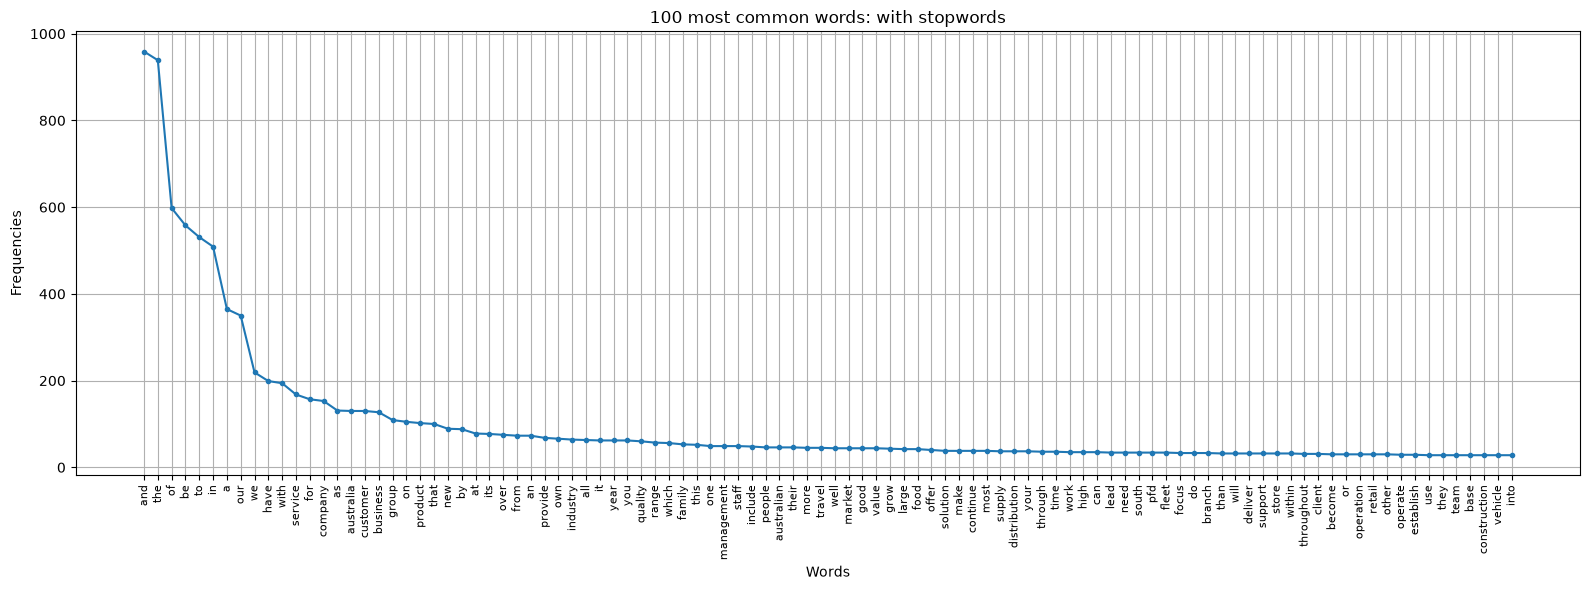

Saved: c:\Research\Subjects\content analysis\MAN7916-main\assignments\submissions\assignment_4\common100_ws.jpg


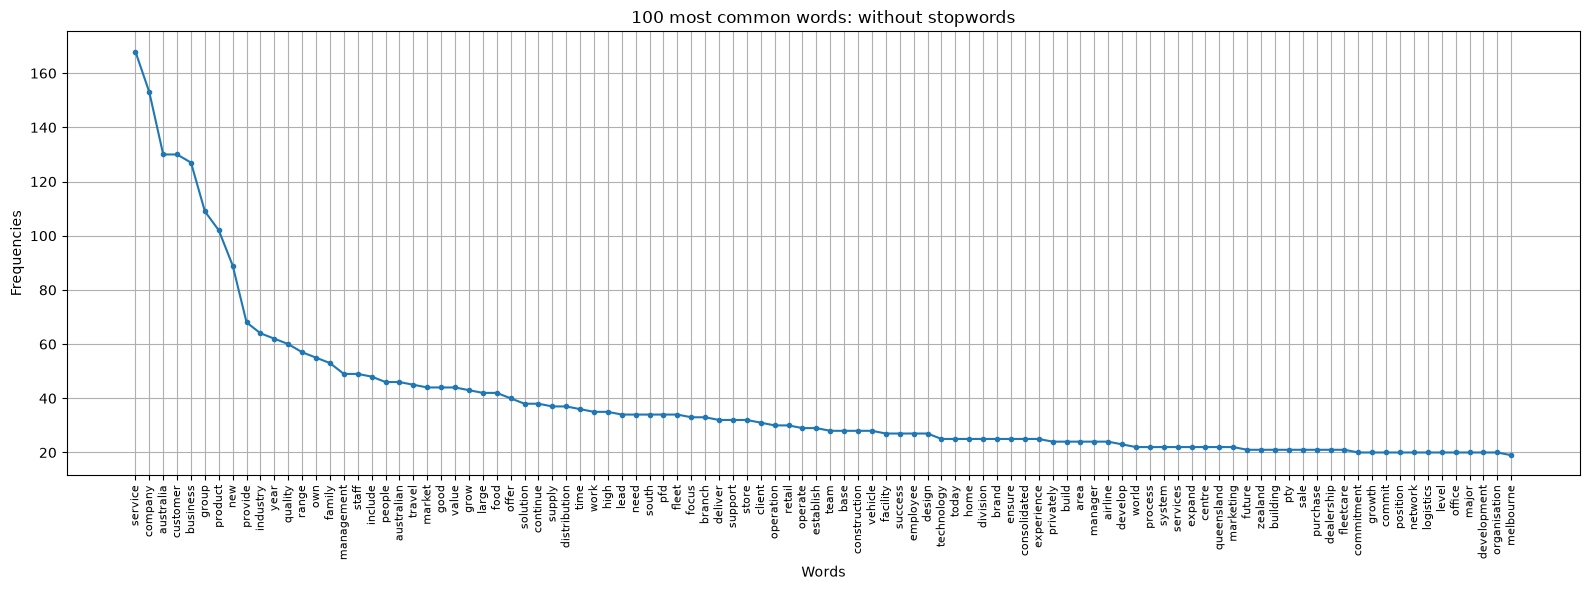

Saved: c:\Research\Subjects\content analysis\MAN7916-main\assignments\submissions\assignment_4\common100_wos.jpg


In [10]:
def plot_common100(word_freq, title, filename):
    sorted_word_freq = word_freq.most_common(100)
    if not sorted_word_freq:
        raise ValueError("No words remain to plot. Check the source texts and preprocessing.")
    words, frequencies = zip(*sorted_word_freq)

    fig, ax = plt.subplots(figsize=(16, 6))
    ax.plot(words, frequencies, marker="o", markersize=3)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.set_xlabel("Words")
    ax.set_ylabel("Frequencies")
    ax.set_title(title)
    ax.grid(True)
    fig.tight_layout()

    chart_path = output_folder / filename
    fig.savefig(chart_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {chart_path}")

plot_common100(word_freq_ws, "100 most common words: with stopwords", "common100_ws.jpg")
plot_common100(word_freq_wos, "100 most common words: without stopwords", "common100_wos.jpg")


## Step 4. Enter the supplied Innovativeness dictionary



In [11]:
innov_dictionary = [
    "ad lib",
    "adroit",
    "adroitness",
    "bright idea",
    "clever",
    "cleverness",
    "conceive",
    "concoct",
    "concoction",
    "concoctive",
    "conjure up",
    "creative",
    "creativity",
    "develop",
    "developed",
    "dream",
    "dream up",
    "expert",
    "formulation",
    "freethinker",
    "genesis",
    "genius",
    "gifted",
    "hit upon",
    "imagination",
    "imaginative",
    "improvise",
    "ingenious",
    "ingenuity",
    "innovate",
    "innovated",
    "innovates",
    "innovating",
    "innovation",
    "innovations",
    "innovative",
    "innovativeness",
    "introduced",
    "introducing",
    "introduction",
    "introductions",
    "invent",
    "invented",
    "invention",
    "inventive",
    "inventiveness",
    "inventor",
    "launch",
    "launched",
    "launching",
    "master stroke",
    "mastermind",
    "metamorphose",
    "metamorphosis",
    "neoteric",
    "neoterism",
    "neoterize",
    "new capabilities",
    "new capability",
    "new compounds",
    "new content",
    "new core areas",
    "new course",
    "new directions",
    "new family",
    "new features",
    "new generation",
    "new generations",
    "new idea",
    "new ideas",
    "new line of business",
    "new medicine",
    "new medicines",
    "new molecular entities",
    "new pharmaceuticals",
    "new platform",
    "new process",
    "new processes",
    "new product",
    "new products",
    "new solutions",
    "new systems",
    "new technique",
    "new techniques",
    "new technologies",
    "new technology",
    "new therapies",
    "new thinking",
    "new tools",
    "new treatments",
    "new ways",
    "new wrinkle",
    "new-generation",
    "new-product",
    "next generation",
    "next-generation",
    "novation",
    "novel",
    "novelty",
    "patent",
    "patented",
    "patents",
    "process development",
    "product development",
    "product launch",
    "product launches",
    "proprietary",
    "prototype",
    "prototyping",
    "push the envelope",
    "R&D",
    "radical",
    "re-engineering",
    "reformulated",
    "refreshed",
    "reinvent",
    "re-invent",
    "reinvented",
    "reinventing",
    "reinvention",
    "reinvents",
    "released",
    "renewal",
    "renewing",
    "research",
    "reshape",
    "reshaped",
    "reshapes",
    "reshaping",
    "resourceful",
    "resourcefulness",
    "restyle",
    "restyling",
    "revolutionary",
    "revolutionize",
    "revolutionized",
    "roll out",
    "rolled out",
    "see things",
    "technologically advanced",
    "think up",
    "trademark",
    "transform",
    "transformation",
    "transformed",
    "transforming",
    "visualize"
]

In [12]:
innov_terms = {}
for term in innov_dictionary:
    tokens = preprocess(term, remove_stopwords=False)
    if not tokens:
        raise ValueError(f"No tokens remain for dictionary entry: {term}")
    normalized_term = " ".join(tokens)
    if normalized_term not in innov_terms:
        innov_terms[normalized_term] = term

# Longer phrases take precedence over their component words.
ordered_terms = sorted(
    innov_terms,
    key=lambda term: (-len(re.findall(r"\S+", term)), -len(term), term),
)
innov_pattern = re.compile(
    r"(?<!\w)(?:" + "|".join(re.escape(term) for term in ordered_terms) + r")(?!\w)"
)

def count_innov_terms(tokens):
    token_text = " ".join(tokens)
    term_freq = Counter()
    for match in innov_pattern.finditer(token_text):
        label = innov_terms[match.group()]
        term_freq[label] += 1
    return term_freq

print(f"Supplied dictionary entries: {len(innov_dictionary)}")
print(f"Unique preprocessed terms: {len(innov_terms)}")

Supplied dictionary entries: 147
Unique preprocessed terms: 112


## Step 5. Plot Innovativeness term frequencies

As in the tutorial, use a `Counter` to keep only dictionary matches and combine
their frequencies across the corpus. Here the matching function extends the
single-word lookup to phrases in the supplied dictionary. Use the **with-stopwords**
version so phrases such as `push the envelope` retain their connecting words.
Save a line chart of the 20 most frequent matched terms, or all terms if fewer
than 20 occur. Only observed terms are plotted.

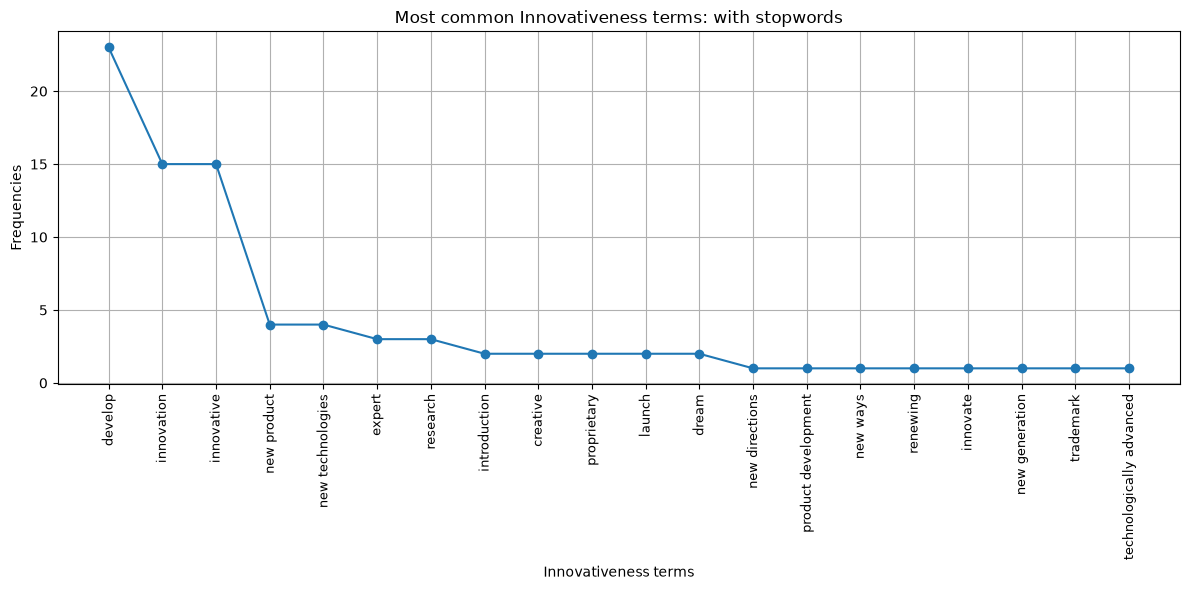

Dictionary frequencies: [('develop', 23), ('innovation', 15), ('innovative', 15), ('new product', 4), ('new technologies', 4), ('expert', 3), ('research', 3), ('introduction', 2), ('creative', 2), ('proprietary', 2), ('launch', 2), ('dream', 2), ('new directions', 1), ('product development', 1), ('new ways', 1), ('renewing', 1), ('innovate', 1), ('new generation', 1), ('trademark', 1), ('technologically advanced', 1), ('introduced', 1), ('released', 1)]
Saved: c:\Research\Subjects\content analysis\MAN7916-main\assignments\submissions\assignment_4\innov_freqs.jpg


In [13]:
innov_counts_by_text = df["preprocessed_ws"].apply(count_innov_terms)

innov_freq = Counter()
for term_freq in innov_counts_by_text:
    innov_freq.update(term_freq)

top_innov_terms = innov_freq.most_common(20)
fig, ax = plt.subplots(figsize=(12, 6))
if top_innov_terms:
    words, frequencies = zip(*top_innov_terms)
    ax.plot(words, frequencies, marker="o")
    ax.tick_params(axis="x", labelrotation=90, labelsize=9)
else:
    ax.text(0.5, 0.5, "No dictionary matches found", ha="center", va="center", transform=ax.transAxes)

ax.set_xlabel("Innovativeness terms")
ax.set_ylabel("Frequencies")
ax.set_title("Most common Innovativeness terms: with stopwords")
ax.grid(True)
fig.tight_layout()
innov_chart_path = output_folder / "innov_freqs.jpg"
fig.savefig(innov_chart_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Dictionary frequencies:", innov_freq.most_common())
print(f"Saved: {innov_chart_path}")

## Step 6. Score each company text

- `innov_ws`: number of nonoverlapping dictionary-term occurrences in
  `preprocessed_ws`. A matching phrase contributes one occurrence.
- `innov_perwd_ws`: that count divided by the number of preprocessed words
  **with stopwords included**, following the tutorial's normalization example.

An empty preprocessed text receives a raw count of zero and a missing normalized
score because its per-word frequency cannot be calculated.

In [14]:
df["innov_ws"] = innov_counts_by_text.apply(lambda term_freq: sum(term_freq.values()))
df["innov_perwd_ws"] = [
    count / len(tokens) if tokens else float("nan")
    for count, tokens in zip(df["innov_ws"], df["preprocessed_ws"])
]

# The corpus-wide Counter must equal the sum of company-level counts.
assert sum(innov_freq.values()) == int(df["innov_ws"].sum())
df[["name", "innov_ws", "innov_perwd_ws"]].head()

,name,innov_ws,innov_perwd_ws
0,1,1,0.003922
1,3,0,0.000000
2,4,0,0.000000
3,5,0,0.000000
4,6,0,0.000000


## Step 7. Save the complete dataset

Save the source fields, both preprocessed token lists, and both Innovativeness
scores. Use `index=False` so the DataFrame's row index does not become an extra
CSV column. Token lists are stored as text representations in the CSV.

In [15]:
csv_columns = [
    "name", "filepath", "text", "preprocessed_ws", "preprocessed_wos",
    "innov_ws", "innov_perwd_ws",
]
csv_path = output_folder / "innov_aussie_data.csv"
df.to_csv(csv_path, columns=csv_columns, index=False, encoding="utf-8")
print(f"Saved {len(df)} company texts to {csv_path}")

Saved 77 company texts to c:\Research\Subjects\content analysis\MAN7916-main\assignments\submissions\assignment_4\innov_aussie_data.csv
